In [1]:

from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. Locate project directory
# --------------------------------------------------

PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

WEATHER_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "weather_operational_combined_2006_2026.csv"
)

print("=" * 65)
print("ENVIRONMENTAL ANOMALY DETECTION")
print("STEP 1: WEATHER DATA INSPECTION")
print("=" * 65)

# --------------------------------------------------
# 2. Check file availability
# --------------------------------------------------

if not WEATHER_FILE.exists():
    raise FileNotFoundError(
        f"Weather dataset not found:\n{WEATHER_FILE}"
    )

print("\nDataset found:")
print(WEATHER_FILE)

# --------------------------------------------------
# 3. Load dataset
# --------------------------------------------------

weather_df = pd.read_csv(WEATHER_FILE)

print("\nDATASET DIMENSIONS")
print("-" * 65)
print(f"Rows: {weather_df.shape[0]:,}")
print(f"Columns: {weather_df.shape[1]}")

# --------------------------------------------------
# 4. Inspect columns and sample records
# --------------------------------------------------

print("\nDATASET COLUMNS")
print("-" * 65)
print(weather_df.columns.tolist())

print("\nFIRST 5 RECORDS")
print("-" * 65)
print(weather_df.head())

# --------------------------------------------------
# 5. Check date coverage
# --------------------------------------------------

print("\nDATE COVERAGE")
print("-" * 65)

weather_df["date"] = pd.to_datetime(
    weather_df["date"],
    errors="coerce"
)

print("Earliest date:", weather_df["date"].min())
print("Latest date:", weather_df["date"].max())
print("Invalid dates:", weather_df["date"].isna().sum())

# --------------------------------------------------
# 6. Check district coverage
# --------------------------------------------------

print("\nDISTRICT COVERAGE")
print("-" * 65)

print("Number of districts:",
      weather_df["district"].nunique())

print("\nDistrict names:")
print(sorted(weather_df["district"].dropna().unique()))

# --------------------------------------------------
# 7. Check important weather variables
# --------------------------------------------------

weather_variables = [
    "precipitation_sum",
    "temperature_2m_mean",
    "relative_humidity_2m_mean"
]

print("\nWEATHER VARIABLE AVAILABILITY")
print("-" * 65)

for column in weather_variables:
    if column in weather_df.columns:
        print(f"\n{column}")
        print("Missing values:", weather_df[column].isna().sum())
        print("Minimum:", weather_df[column].min())
        print("Maximum:", weather_df[column].max())
    else:
        print(f"\n{column}: NOT FOUND")

# --------------------------------------------------
# 8. Missing-value summary
# --------------------------------------------------

print("\nMISSING VALUE SUMMARY")
print("-" * 65)

missing_summary = (
    weather_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

print(missing_summary[missing_summary > 0])

print("\nSTEP 1 INSPECTION COMPLETED.")


ENVIRONMENTAL ANOMALY DETECTION
STEP 1: WEATHER DATA INSPECTION

Dataset found:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\weather_operational_combined_2006_2026.csv

DATASET DIMENSIONS
-----------------------------------------------------------------
Rows: 181,550
Columns: 28

DATASET COLUMNS
-----------------------------------------------------------------
['district', 'date', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'cloud_cover_mean', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'requested_latitude', 'requested_longitude', 'era5_grid_latitude', 'era5_grid_longitude', 'era5_grid_elevation_m', 'model', 'timezone', 'data_source', 'hourly_observation_count', 'retrieved_at']

FIRST 5 RECORDS
---------

In [2]:

# ============================================================
# STEP 2: DATA QUALITY AND DAILY CONTINUITY CHECKS
# ============================================================

print("=" * 65)
print("ENVIRONMENTAL ANOMALY DETECTION")
print("STEP 2: DATA QUALITY AND CONTINUITY")
print("=" * 65)

# ------------------------------------------------------------
# 1. Required columns
# ------------------------------------------------------------

required_columns = [
    "district",
    "date",
    "precipitation_sum",
    "temperature_2m_mean",
    "relative_humidity_2m_mean"
]

missing_columns = [
    col for col in required_columns
    if col not in weather_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

analysis_df = weather_df[required_columns].copy()

analysis_df["date"] = pd.to_datetime(
    analysis_df["date"]
)

# ------------------------------------------------------------
# 2. Duplicate district-date records
# ------------------------------------------------------------

print("\n1. DUPLICATE RECORD ANALYSIS")
print("-" * 65)

duplicate_count = analysis_df.duplicated(
    subset=["district", "date"]
).sum()

print("Duplicate district-date records:", duplicate_count)

# ------------------------------------------------------------
# 3. Missing values in selected variables
# ------------------------------------------------------------

print("\n2. SELECTED VARIABLE MISSING VALUES")
print("-" * 65)

print(
    analysis_df[
        required_columns[2:]
    ].isnull().sum()
)

# ------------------------------------------------------------
# 4. District-level record counts
# ------------------------------------------------------------

print("\n3. DISTRICT RECORD COUNTS")
print("-" * 65)

district_counts = (
    analysis_df.groupby("district")
    .agg(
        total_records=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        unique_dates=("date", "nunique")
    )
    .sort_index()
)

print(district_counts.to_string())

# ------------------------------------------------------------
# 5. Check missing calendar days per district
# ------------------------------------------------------------

print("\n4. DAILY DATE CONTINUITY")
print("-" * 65)

continuity_results = []

for district, group in analysis_df.groupby("district"):

    dates = (
        group["date"]
        .dropna()
        .drop_duplicates()
        .sort_values()
    )

    expected_dates = pd.date_range(
        start=dates.min(),
        end=dates.max(),
        freq="D"
    )

    missing_dates = expected_dates.difference(dates)

    continuity_results.append({
        "district": district,
        "expected_days": len(expected_dates),
        "available_days": len(dates),
        "missing_days": len(missing_dates)
    })

continuity_df = pd.DataFrame(continuity_results)

print(continuity_df.to_string(index=False))

# ------------------------------------------------------------
# 6. Physical range checks
# ------------------------------------------------------------

print("\n5. WEATHER VALUE RANGE CHECKS")
print("-" * 65)

range_checks = {
    "precipitation_sum": (
        analysis_df["precipitation_sum"] < 0
    ),
    "relative_humidity_2m_mean": (
        (analysis_df["relative_humidity_2m_mean"] < 0) |
        (analysis_df["relative_humidity_2m_mean"] > 100)
    ),
    "temperature_2m_mean": (
        analysis_df["temperature_2m_mean"].isna()
    )
}

for variable, condition in range_checks.items():
    print(f"{variable}: {condition.sum()} flagged records")

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("\n6. QUALITY CHECK SUMMARY")
print("-" * 65)

print("Total records:", len(analysis_df))
print("Duplicate records:", duplicate_count)
print(
    "Total missing calendar days:",
    continuity_df["missing_days"].sum()
)

print("\nSTEP 2 COMPLETED.")


ENVIRONMENTAL ANOMALY DETECTION
STEP 2: DATA QUALITY AND CONTINUITY

1. DUPLICATE RECORD ANALYSIS
-----------------------------------------------------------------
Duplicate district-date records: 0

2. SELECTED VARIABLE MISSING VALUES
-----------------------------------------------------------------
precipitation_sum            0
temperature_2m_mean          0
relative_humidity_2m_mean    0
dtype: int64

3. DISTRICT RECORD COUNTS
-----------------------------------------------------------------
              total_records first_date  last_date  unique_dates
district                                                       
Ampara                 7262 2006-12-23 2026-11-09          7262
Anuradhapura           7262 2006-12-23 2026-11-09          7262
Badulla                7262 2006-12-23 2026-11-09          7262
Batticaloa             7262 2006-12-23 2026-11-09          7262
Colombo                7262 2006-12-23 2026-11-09          7262
Galle                  7262 2006-12-23 2026-11-09  

In [3]:

# ============================================================
# STEP 3: HISTORICAL SEASONAL BASELINE
# ============================================================

print("=" * 65)
print("ENVIRONMENTAL ANOMALY DETECTION")
print("STEP 3: HISTORICAL SEASONAL BASELINE")
print("=" * 65)

# ------------------------------------------------------------
# 1. Prepare baseline dataset
# ------------------------------------------------------------

baseline_df = analysis_df.copy()

baseline_df["year"] = baseline_df["date"].dt.year
baseline_df["month"] = baseline_df["date"].dt.month

BASELINE_START_YEAR = 2007
BASELINE_END_YEAR = 2025

baseline_history = baseline_df[
    baseline_df["year"].between(
        BASELINE_START_YEAR,
        BASELINE_END_YEAR
    )
].copy()

print("\nBASELINE PERIOD")
print("-" * 65)
print(f"Start year: {BASELINE_START_YEAR}")
print(f"End year: {BASELINE_END_YEAR}")
print(f"Historical records: {len(baseline_history):,}")
print(
    "Districts:",
    baseline_history["district"].nunique()
)

# ------------------------------------------------------------
# 2. Calculate district-month percentile thresholds
# ------------------------------------------------------------

baseline_thresholds = (
    baseline_history
    .groupby(["district", "month"])
    .agg(
        rainfall_q01=("precipitation_sum",
                      lambda x: x.quantile(0.01)),

        rainfall_q99=("precipitation_sum",
                      lambda x: x.quantile(0.99)),

        temperature_q01=("temperature_2m_mean",
                         lambda x: x.quantile(0.01)),

        temperature_q99=("temperature_2m_mean",
                         lambda x: x.quantile(0.99)),

        humidity_q01=("relative_humidity_2m_mean",
                      lambda x: x.quantile(0.01)),

        humidity_q99=("relative_humidity_2m_mean",
                      lambda x: x.quantile(0.99)),

        baseline_observations=("date", "count")
    )
    .reset_index()
)

print("\nBASELINE THRESHOLD SUMMARY")
print("-" * 65)

print("Number of district-month groups:",
      len(baseline_thresholds))

print("Expected groups:",
      25 * 12)

print("\nObservations per group:")
print(
    baseline_thresholds[
        "baseline_observations"
    ].describe()
)

# ------------------------------------------------------------
# 3. Check threshold validity
# ------------------------------------------------------------

print("\nTHRESHOLD VALIDATION")
print("-" * 65)

threshold_columns = [
    "rainfall_q01",
    "rainfall_q99",
    "temperature_q01",
    "temperature_q99",
    "humidity_q01",
    "humidity_q99"
]

print(
    "Missing threshold values:",
    baseline_thresholds[threshold_columns]
    .isnull().sum().sum()
)

print(
    "Invalid rainfall ordering:",
    (
        baseline_thresholds["rainfall_q01"]
        > baseline_thresholds["rainfall_q99"]
    ).sum()
)

print(
    "Invalid temperature ordering:",
    (
        baseline_thresholds["temperature_q01"]
        > baseline_thresholds["temperature_q99"]
    ).sum()
)

print(
    "Invalid humidity ordering:",
    (
        baseline_thresholds["humidity_q01"]
        > baseline_thresholds["humidity_q99"]
    ).sum()
)

# ------------------------------------------------------------
# 4. Display sample thresholds
# ------------------------------------------------------------

print("\nSAMPLE DISTRICT THRESHOLDS")
print("-" * 65)

sample_districts = [
    "Colombo",
    "Kandy",
    "Jaffna",
    "Nuwara Eliya",
    "Galle"
]

sample_thresholds = baseline_thresholds[
    baseline_thresholds["district"].isin(
        sample_districts
    )
]

print(
    sample_thresholds[
        [
            "district",
            "month",
            "rainfall_q99",
            "temperature_q01",
            "temperature_q99",
            "humidity_q01",
            "humidity_q99",
            "baseline_observations"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 5. Save baseline thresholds
# ------------------------------------------------------------

BASELINE_DIR = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "environmental_anomalies"
)

BASELINE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BASELINE_FILE = (
    BASELINE_DIR
    / "district_monthly_weather_baselines.csv"
)

baseline_thresholds.to_csv(
    BASELINE_FILE,
    index=False
)

print("\nBASELINE FILE SAVED")
print("-" * 65)
print(BASELINE_FILE)

print("\nSTEP 3 COMPLETED.")


ENVIRONMENTAL ANOMALY DETECTION
STEP 3: HISTORICAL SEASONAL BASELINE

BASELINE PERIOD
-----------------------------------------------------------------
Start year: 2007
End year: 2025
Historical records: 173,500
Districts: 25

BASELINE THRESHOLD SUMMARY
-----------------------------------------------------------------
Number of district-month groups: 300
Expected groups: 300

Observations per group:
count    300.000000
mean     578.333333
std       15.253342
min      537.000000
25%      570.000000
50%      589.000000
75%      589.000000
max      589.000000
Name: baseline_observations, dtype: float64

THRESHOLD VALIDATION
-----------------------------------------------------------------
Missing threshold values: 0
Invalid rainfall ordering: 0
Invalid temperature ordering: 0
Invalid humidity ordering: 0

SAMPLE DISTRICT THRESHOLDS
-----------------------------------------------------------------
    district  month  rainfall_q99  temperature_q01  temperature_q99  humidity_q01  humidity_q

In [4]:

# ============================================================
# STEP 4: ENVIRONMENTAL ANOMALY DETECTION
# ============================================================

print("=" * 65)
print("ENVIRONMENTAL ANOMALY DETECTION")
print("STEP 4: DETECTING WEATHER ANOMALIES")
print("=" * 65)

# ------------------------------------------------------------
# 1. Prepare 2026 observations
# ------------------------------------------------------------

detection_df = analysis_df.copy()

detection_df["year"] = detection_df["date"].dt.year
detection_df["month"] = detection_df["date"].dt.month

# Detect anomalies in 2026 only
detection_df = detection_df[
    detection_df["year"] == 2026
].copy()

print("\nDETECTION DATA")
print("-" * 65)
print("Records:", len(detection_df))
print("Districts:", detection_df["district"].nunique())
print("Start date:", detection_df["date"].min())
print("End date:", detection_df["date"].max())

# ------------------------------------------------------------
# 2. Merge historical district-month thresholds
# ------------------------------------------------------------

detection_df = detection_df.merge(
    baseline_thresholds,
    on=["district", "month"],
    how="left",
    validate="many_to_one"
)

if detection_df[threshold_columns].isna().any().any():
    raise ValueError(
        "Some observations do not have historical thresholds."
    )

# ------------------------------------------------------------
# 3. Detect rainfall anomalies
# ------------------------------------------------------------

detection_df["rainfall_anomaly"] = (
    detection_df["precipitation_sum"]
    > detection_df["rainfall_q99"]
)

detection_df["rainfall_anomaly_type"] = ""

detection_df.loc[
    detection_df["rainfall_anomaly"],
    "rainfall_anomaly_type"
] = "Unusually high rainfall"

# ------------------------------------------------------------
# 4. Detect temperature anomalies
# ------------------------------------------------------------

detection_df["temperature_low_anomaly"] = (
    detection_df["temperature_2m_mean"]
    < detection_df["temperature_q01"]
)

detection_df["temperature_high_anomaly"] = (
    detection_df["temperature_2m_mean"]
    > detection_df["temperature_q99"]
)

detection_df["temperature_anomaly"] = (
    detection_df["temperature_low_anomaly"]
    | detection_df["temperature_high_anomaly"]
)

detection_df["temperature_anomaly_type"] = ""

detection_df.loc[
    detection_df["temperature_low_anomaly"],
    "temperature_anomaly_type"
] = "Unusually low temperature"

detection_df.loc[
    detection_df["temperature_high_anomaly"],
    "temperature_anomaly_type"
] = "Unusually high temperature"

# ------------------------------------------------------------
# 5. Detect relative humidity anomalies
# ------------------------------------------------------------

detection_df["humidity_low_anomaly"] = (
    detection_df["relative_humidity_2m_mean"]
    < detection_df["humidity_q01"]
)

detection_df["humidity_high_anomaly"] = (
    detection_df["relative_humidity_2m_mean"]
    > detection_df["humidity_q99"]
)

detection_df["humidity_anomaly"] = (
    detection_df["humidity_low_anomaly"]
    | detection_df["humidity_high_anomaly"]
)

detection_df["humidity_anomaly_type"] = ""

detection_df.loc[
    detection_df["humidity_low_anomaly"],
    "humidity_anomaly_type"
] = "Unusually low humidity"

detection_df.loc[
    detection_df["humidity_high_anomaly"],
    "humidity_anomaly_type"
] = "Unusually high humidity"

# ------------------------------------------------------------
# 6. Calculate daily anomaly counts
# ------------------------------------------------------------

anomaly_flag_columns = [
    "rainfall_anomaly",
    "temperature_anomaly",
    "humidity_anomaly"
]

detection_df["anomaly_count"] = (
    detection_df[anomaly_flag_columns]
    .sum(axis=1)
)

detection_df["any_anomaly"] = (
    detection_df["anomaly_count"] > 0
)

# Descriptive classification, not dengue-risk classification
detection_df["anomaly_category"] = "No detected anomaly"

detection_df.loc[
    detection_df["anomaly_count"] == 1,
    "anomaly_category"
] = "Single-variable anomaly"

detection_df.loc[
    detection_df["anomaly_count"] == 2,
    "anomaly_category"
] = "Two-variable anomaly"

detection_df.loc[
    detection_df["anomaly_count"] == 3,
    "anomaly_category"
] = "Multi-variable anomaly"

# ------------------------------------------------------------
# 7. Overall anomaly summary
# ------------------------------------------------------------

print("\nOVERALL ANOMALY SUMMARY")
print("-" * 65)

for column, label in [
    ("rainfall_anomaly", "Rainfall anomalies"),
    ("temperature_anomaly", "Temperature anomalies"),
    ("humidity_anomaly", "Humidity anomalies"),
    ("any_anomaly", "Days with at least one anomaly")
]:
    count = int(detection_df[column].sum())
    percentage = count / len(detection_df) * 100

    print(
        f"{label}: {count:,} ({percentage:.2f}%)"
    )

print("\nANOMALY CATEGORY COUNTS")
print("-" * 65)

print(
    detection_df["anomaly_category"]
    .value_counts()
    .to_string()
)

# ------------------------------------------------------------
# 8. District-level summary
# ------------------------------------------------------------

print("\nDISTRICT-LEVEL ANOMALY SUMMARY")
print("-" * 65)

district_anomaly_summary = (
    detection_df
    .groupby("district")
    .agg(
        total_days=("date", "count"),
        rainfall_anomalies=("rainfall_anomaly", "sum"),
        temperature_anomalies=("temperature_anomaly", "sum"),
        humidity_anomalies=("humidity_anomaly", "sum"),
        days_with_anomalies=("any_anomaly", "sum")
    )
    .reset_index()
)

district_anomaly_summary["anomaly_percentage"] = (
    district_anomaly_summary["days_with_anomalies"]
    / district_anomaly_summary["total_days"]
    * 100
)

district_anomaly_summary = (
    district_anomaly_summary
    .sort_values(
        "days_with_anomalies",
        ascending=False
    )
)

print(district_anomaly_summary.to_string(index=False))

# ------------------------------------------------------------
# 9. Save anomaly detection outputs
# ------------------------------------------------------------

ANOMALY_DIR = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "environmental_anomalies"
)

ANOMALY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

daily_output_file = (
    ANOMALY_DIR
    / "weather_anomaly_daily_2026.csv"
)

summary_output_file = (
    ANOMALY_DIR
    / "district_anomaly_summary_2026.csv"
)

detection_df.to_csv(
    daily_output_file,
    index=False
)

district_anomaly_summary.to_csv(
    summary_output_file,
    index=False
)

print("\nOUTPUT FILES SAVED")
print("-" * 65)
print(daily_output_file)
print(summary_output_file)

print("\nSTEP 4 COMPLETED.")


ENVIRONMENTAL ANOMALY DETECTION
STEP 4: DETECTING WEATHER ANOMALIES

DETECTION DATA
-----------------------------------------------------------------
Records: 7825
Districts: 25
Start date: 2026-01-01 00:00:00
End date: 2026-11-09 00:00:00

OVERALL ANOMALY SUMMARY
-----------------------------------------------------------------
Rainfall anomalies: 69 (0.88%)
Temperature anomalies: 254 (3.25%)
Humidity anomalies: 121 (1.55%)
Days with at least one anomaly: 414 (5.29%)

ANOMALY CATEGORY COUNTS
-----------------------------------------------------------------
anomaly_category
No detected anomaly        7411
Single-variable anomaly     385
Two-variable anomaly         28
Multi-variable anomaly        1

DISTRICT-LEVEL ANOMALY SUMMARY
-----------------------------------------------------------------
    district  total_days  rainfall_anomalies  temperature_anomalies  humidity_anomalies  days_with_anomalies  anomaly_percentage
    Puttalam         313                   5                    

ENVIRONMENTAL ANOMALY DETECTION
STEP 5: ANOMALY ANALYSIS AND VISUALIZATION

MONTHLY ANOMALY SUMMARY
-----------------------------------------------------------------
month_name  total_observations  rainfall_anomalies  temperature_anomalies  humidity_anomalies  days_with_anomalies  anomaly_percentage
   January                 775                   3                      2                   7                   12            1.548387
  February                 700                   9                      4                   1                   13            1.857143
     March                 775                   1                     26                   4                   31            4.000000
     April                 750                   5                      9                   5                   19            2.533333
       May                 775                   6                      9                  19                   32            4.129032
      June              

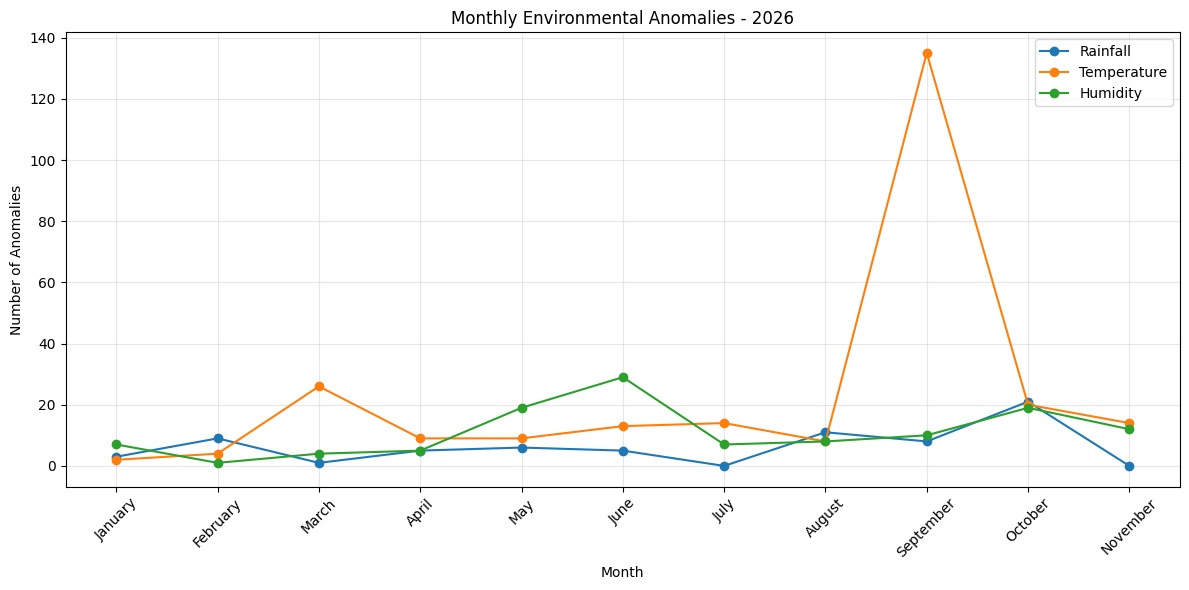

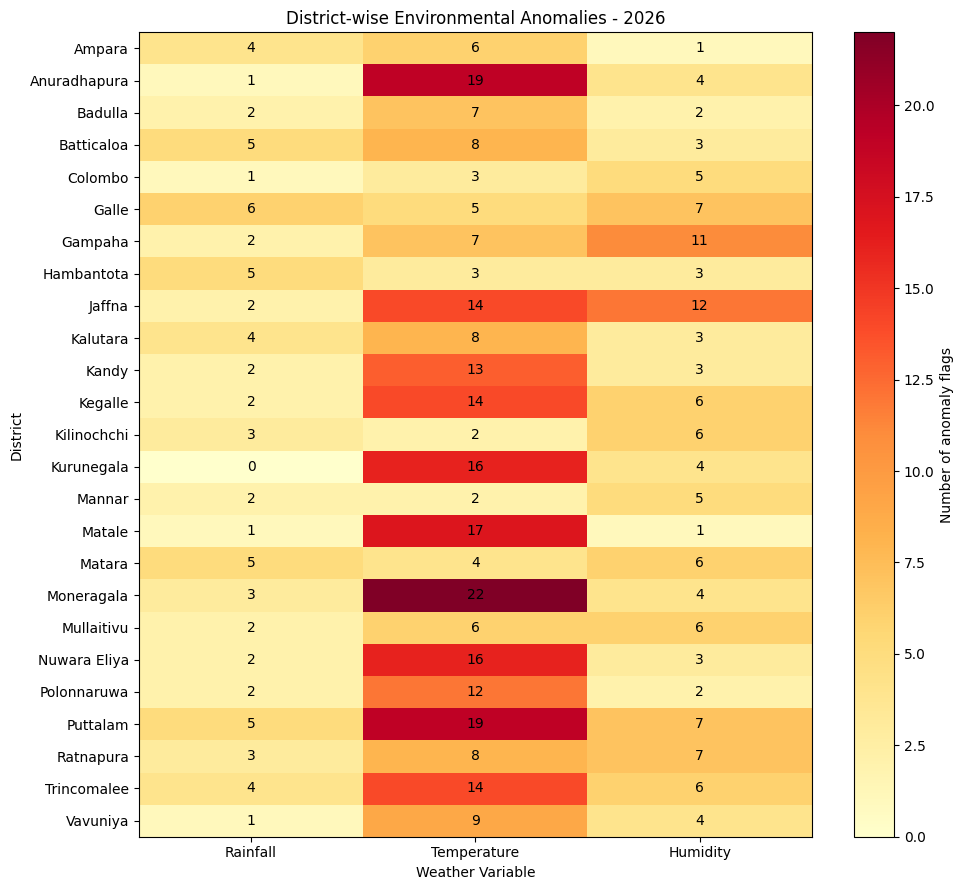


OUTPUT FILES
-----------------------------------------------------------------
c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\environmental_anomalies\monthly_anomaly_summary_2026.csv
c:\Users\Nethmi\Documents\GitHub\RiskWeave\reports\environmental_anomalies\monthly_anomaly_trends_2026.png
c:\Users\Nethmi\Documents\GitHub\RiskWeave\reports\environmental_anomalies\district_anomaly_heatmap_2026.png

STEP 5 COMPLETED.


In [5]:

# ============================================================
# STEP 5: ANOMALY ANALYSIS AND VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

print("=" * 65)
print("ENVIRONMENTAL ANOMALY DETECTION")
print("STEP 5: ANOMALY ANALYSIS AND VISUALIZATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Monthly anomaly summary
# ------------------------------------------------------------

monthly_summary = (
    detection_df
    .groupby("month")
    .agg(
        total_observations=("date", "count"),
        rainfall_anomalies=("rainfall_anomaly", "sum"),
        temperature_anomalies=("temperature_anomaly", "sum"),
        humidity_anomalies=("humidity_anomaly", "sum"),
        days_with_anomalies=("any_anomaly", "sum")
    )
    .reset_index()
)

monthly_summary["anomaly_percentage"] = (
    monthly_summary["days_with_anomalies"]
    / monthly_summary["total_observations"]
    * 100
)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_summary["month_name"] = (
    monthly_summary["month"].map(month_names)
)

print("\nMONTHLY ANOMALY SUMMARY")
print("-" * 65)

print(
    monthly_summary[
        [
            "month_name",
            "total_observations",
            "rainfall_anomalies",
            "temperature_anomalies",
            "humidity_anomalies",
            "days_with_anomalies",
            "anomaly_percentage"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 2. Create output directories
# ------------------------------------------------------------

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "environmental_anomalies"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Monthly anomaly trend chart
# ------------------------------------------------------------

plot_data = monthly_summary.copy()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    plot_data["month_name"],
    plot_data["rainfall_anomalies"],
    marker="o",
    label="Rainfall"
)

ax.plot(
    plot_data["month_name"],
    plot_data["temperature_anomalies"],
    marker="o",
    label="Temperature"
)

ax.plot(
    plot_data["month_name"],
    plot_data["humidity_anomalies"],
    marker="o",
    label="Humidity"
)

ax.set_title("Monthly Environmental Anomalies - 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Anomalies")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

monthly_chart_file = (
    REPORT_DIR / "monthly_anomaly_trends_2026.png"
)

plt.savefig(
    monthly_chart_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. District anomaly heatmap
# ------------------------------------------------------------

heatmap_data = (
    detection_df
    .groupby("district")[
        [
            "rainfall_anomaly",
            "temperature_anomaly",
            "humidity_anomaly"
        ]
    ]
    .sum()
)

heatmap_data = heatmap_data.sort_index()

fig, ax = plt.subplots(figsize=(10, 9))

image = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_xticks(
    np.arange(len(heatmap_data.columns))
)

ax.set_xticklabels(
    [
        "Rainfall",
        "Temperature",
        "Humidity"
    ]
)

ax.set_yticks(
    np.arange(len(heatmap_data.index))
)

ax.set_yticklabels(heatmap_data.index)

ax.set_title("District-wise Environmental Anomalies - 2026")
ax.set_xlabel("Weather Variable")
ax.set_ylabel("District")

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        ax.text(
            j,
            i,
            int(heatmap_data.iloc[i, j]),
            ha="center",
            va="center"
        )

fig.colorbar(
    image,
    ax=ax,
    label="Number of anomaly flags"
)

plt.tight_layout()

heatmap_file = (
    REPORT_DIR / "district_anomaly_heatmap_2026.png"
)

plt.savefig(
    heatmap_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 5. Save monthly summary
# ------------------------------------------------------------

monthly_summary_file = (
    ANOMALY_DIR / "monthly_anomaly_summary_2026.csv"
)

monthly_summary.to_csv(
    monthly_summary_file,
    index=False
)

print("\nOUTPUT FILES")
print("-" * 65)
print(monthly_summary_file)
print(monthly_chart_file)
print(heatmap_file)

print("\nSTEP 5 COMPLETED.")


In [6]:

# ============================================================
# STEP 6: INVESTIGATE SEPTEMBER TEMPERATURE ANOMALIES
# ============================================================

print("=" * 65)
print("ENVIRONMENTAL ANOMALY DETECTION")
print("STEP 6: SEPTEMBER TEMPERATURE INVESTIGATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Extract September temperature anomalies
# ------------------------------------------------------------

september_temp = detection_df[
    (detection_df["month"] == 9) &
    (detection_df["temperature_anomaly"])
].copy()

print("\nSEPTEMBER TEMPERATURE ANOMALY COUNTS")
print("-" * 65)

print("Total anomalies:", len(september_temp))

print(
    "Unusually high:",
    september_temp["temperature_high_anomaly"].sum()
)

print(
    "Unusually low:",
    september_temp["temperature_low_anomaly"].sum()
)

# ------------------------------------------------------------
# 2. District-level investigation
# ------------------------------------------------------------

print("\nDISTRICT-LEVEL TEMPERATURE ANOMALIES")
print("-" * 65)

september_district_summary = (
    september_temp
    .groupby("district")
    .agg(
        anomaly_count=("date", "count"),
        mean_temperature=("temperature_2m_mean", "mean"),
        maximum_temperature=("temperature_2m_mean", "max"),
        minimum_temperature=("temperature_2m_mean", "min"),
        mean_upper_threshold=("temperature_q99", "mean"),
        mean_lower_threshold=("temperature_q01", "mean")
    )
    .reset_index()
    .sort_values("anomaly_count", ascending=False)
)

print(september_district_summary.to_string(index=False))

# ------------------------------------------------------------
# 3. Date-level investigation
# ------------------------------------------------------------

print("\nDATE-LEVEL TEMPERATURE ANOMALIES")
print("-" * 65)

september_date_summary = (
    september_temp
    .groupby("date")
    .agg(
        affected_districts=("district", "nunique"),
        mean_temperature=("temperature_2m_mean", "mean"),
        maximum_temperature=("temperature_2m_mean", "max"),
        minimum_temperature=("temperature_2m_mean", "min"),
        high_anomalies=("temperature_high_anomaly", "sum"),
        low_anomalies=("temperature_low_anomaly", "sum")
    )
    .reset_index()
    .sort_values(
        "affected_districts",
        ascending=False
    )
)

print(september_date_summary.to_string(index=False))

# ------------------------------------------------------------
# 4. Inspect individual anomaly records
# ------------------------------------------------------------

print("\nINDIVIDUAL ANOMALY RECORDS")
print("-" * 65)

inspection_columns = [
    "district",
    "date",
    "temperature_2m_mean",
    "temperature_q01",
    "temperature_q99",
    "temperature_low_anomaly",
    "temperature_high_anomaly"
]

print(
    september_temp[inspection_columns]
    .sort_values(["date", "district"])
    .to_string(index=False)
)

# ------------------------------------------------------------
# 5. Save investigation results
# ------------------------------------------------------------

investigation_file = (
    ANOMALY_DIR
    / "september_temperature_investigation_2026.csv"
)

september_temp[inspection_columns].to_csv(
    investigation_file,
    index=False
)

print("\nINVESTIGATION FILE SAVED")
print(investigation_file)

print("\nSTEP 6 COMPLETED.")


ENVIRONMENTAL ANOMALY DETECTION
STEP 6: SEPTEMBER TEMPERATURE INVESTIGATION

SEPTEMBER TEMPERATURE ANOMALY COUNTS
-----------------------------------------------------------------
Total anomalies: 135
Unusually high: 135
Unusually low: 0

DISTRICT-LEVEL TEMPERATURE ANOMALIES
-----------------------------------------------------------------
    district  anomaly_count  mean_temperature  maximum_temperature  minimum_temperature  mean_upper_threshold  mean_lower_threshold
Anuradhapura             14         29.892857                 30.5                 29.5                29.431                25.469
      Matale             14         28.671429                 29.3                 28.3                28.200                24.169
  Moneragala             11         28.863636                 29.4                 28.3                28.200                22.900
Nuwara Eliya             11         15.209091                 15.4                 15.1                15.000                12.20

In [8]:

# ============================================================
# STEP 7: VALIDATE SEPTEMBER TEMPERATURE ANOMALIES
# ============================================================

print("=" * 65)
print("ENVIRONMENTAL ANOMALY DETECTION")
print("STEP 7: SEPTEMBER TEMPERATURE VALIDATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Extract historical September observations
# ------------------------------------------------------------

historical_september = baseline_history[
    baseline_history["month"] == 9
].copy()

current_september = detection_df[
    detection_df["month"] == 9
].copy()

# ------------------------------------------------------------
# 2. Calculate historical district statistics
# ------------------------------------------------------------

historical_stats = (
    historical_september
    .groupby("district")
    .agg(
        historical_mean_temperature=(
            "temperature_2m_mean", "mean"
        ),
        historical_std_temperature=(
            "temperature_2m_mean", "std"
        ),
        historical_observations=(
            "temperature_2m_mean", "count"
        ),
        historical_q99=(
            "temperature_2m_mean",
            lambda x: x.quantile(0.99)
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. Calculate September 2026 district statistics
# ------------------------------------------------------------

current_stats = (
    current_september
    .groupby("district")
    .agg(
        current_mean_temperature=(
            "temperature_2m_mean", "mean"
        ),
        current_max_temperature=(
            "temperature_2m_mean", "max"
        ),
        current_min_temperature=(
            "temperature_2m_mean", "min"
        ),
        current_observations=(
            "temperature_2m_mean", "count"
        ),
        current_high_anomalies=(
            "temperature_high_anomaly", "sum"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. Combine historical and current statistics
# ------------------------------------------------------------

september_comparison = historical_stats.merge(
    current_stats,
    on="district",
    how="inner",
    validate="one_to_one"
)

september_comparison["temperature_difference"] = (
    september_comparison["current_mean_temperature"]
    - september_comparison["historical_mean_temperature"]
)

september_comparison["temperature_z_score"] = (
    september_comparison["temperature_difference"]
    / september_comparison["historical_std_temperature"]
)


# ------------------------------------------------------------
# 5. Display district comparison
# ------------------------------------------------------------

september_comparison = september_comparison.sort_values(
    "temperature_difference",
    ascending=False
)

print("\nHISTORICAL VS 2026 SEPTEMBER TEMPERATURE")
print("-" * 65)

comparison_columns = [
    "district",
    "historical_mean_temperature",
    "current_mean_temperature",
    "temperature_difference",
    "historical_std_temperature",
    "temperature_z_score",
    "current_high_anomalies"
]

print(
    september_comparison[comparison_columns]
    .round(3)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 6. Overall temperature comparison
# ------------------------------------------------------------

print("\nOVERALL SEPTEMBER COMPARISON")
print("-" * 65)

historical_overall_mean = (
    historical_september["temperature_2m_mean"].mean()
)

current_overall_mean = (
    current_september["temperature_2m_mean"].mean()
)

print("Historical mean temperature:",
      round(historical_overall_mean, 3), "°C")

print("2026 mean temperature:",
      round(current_overall_mean, 3), "°C")

print(
    "Overall temperature difference:",
    round(current_overall_mean - historical_overall_mean, 3),
    "°C"
)

print(
    "Districts with higher September 2026 means:",
    (
        september_comparison["temperature_difference"] > 0
    ).sum()
)

# ------------------------------------------------------------
# 7. Check historical exceedance counts
# ------------------------------------------------------------

historical_september = historical_september.merge(
    baseline_thresholds[
        ["district", "month", "temperature_q99"]
    ],
    on=["district", "month"],
    how="left",
    validate="many_to_one"
)

historical_exceedances = (
    historical_september["temperature_2m_mean"]
    > historical_september["temperature_q99"]
).sum()

current_exceedances = (
    current_september["temperature_high_anomaly"].sum()
)

print("\nPERCENTILE THRESHOLD COMPARISON")
print("-" * 65)

print(
    "Historical September observations above Q99:",
    int(historical_exceedances)
)

print(
    "Historical exceedance percentage:",
    round(
        historical_exceedances
        / len(historical_september) * 100,
        3
    ),
    "%"
)

print(
    "2026 September observations above Q99:",
    int(current_exceedances)
)

print(
    "2026 exceedance percentage:",
    round(
        current_exceedances
        / len(current_september) * 100,
        3
    ),
    "%"
)

# ------------------------------------------------------------
# 8. Save comparison
# ------------------------------------------------------------

comparison_file = (
    ANOMALY_DIR
    / "september_temperature_historical_comparison_2026.csv"
)

september_comparison.to_csv(
    comparison_file,
    index=False
)

print("\nCOMPARISON FILE SAVED")
print(comparison_file)

print("\nSTEP 7 COMPLETED.")


ENVIRONMENTAL ANOMALY DETECTION
STEP 7: SEPTEMBER TEMPERATURE VALIDATION

HISTORICAL VS 2026 SEPTEMBER TEMPERATURE
-----------------------------------------------------------------
    district  historical_mean_temperature  current_mean_temperature  temperature_difference  historical_std_temperature  temperature_z_score  current_high_anomalies
 Trincomalee                       29.028                    30.460                   1.432                       1.016                1.410                      10
  Moneragala                       25.797                    27.197                   1.400                       1.203                1.164                      11
      Matale                       26.676                    27.967                   1.291                       0.845                1.527                      14
  Batticaloa                       29.282                    30.563                   1.281                       1.249                1.026                   